In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
from windrose import WindroseAxes  #using https://pypi.org/project/windrose/
import glob
import os
from datetime import datetime, timedelta

In [4]:
# mask
lat_min, lat_max = -34.14, -33.55
lon_min, lon_max = 150.57, 151.37

# using any scenario but the bulk
file_luindex = "/g/data/fy29/mf9078/run_WRF/etamodified/output/4out/wrfout_d02_2017-01-12_21:00:00"
ds_mask = xr.open_dataset(file_luindex) 
XLAT = ds_mask["XLAT"]
XLONG = ds_mask["XLONG"]
LU_INDEX = ds_mask["LU_INDEX"]
lat_mask = (XLAT >= lat_min) & (XLAT <= lat_max)
lon_mask = (XLONG >= lon_min) & (XLONG <= lon_max)
lu_mask = (LU_INDEX >= 51) & (LU_INDEX <= 60)
region_mask = lat_mask & lon_mask & lu_mask
ds_mask.close()

print(f"Region mask covers {region_mask.sum().values} grid points")

Region mask covers 1629 grid points


In [5]:
# Data processing for the windrose plot for the whole period
paths = {
    "Bulk": "/g/data/fy29/mf9078/run_WRF/etamodified/output/0out/",
    "LCZ": "/g/data/fy29/mf9078/run_WRF/etamodified/output/1out/",
    "WSF-MB": "/g/data/fy29/mf9078/run_WRF/etamodified/output/3out/animation/",
    "Geoscape": "/g/data/fy29/mf9078/run_WRF/etamodified/output/4out/"
}

# Dictionary to store all wind data for each scenario
scenario_data = {}

# Process each scenario
for scenario_name, path in paths.items():
    print(f"\nProcessing {scenario_name}...")
    
    # Get all files for this scenario
    file_pattern = os.path.join(path, "wrfout_d02_2017-01-*")
    file_list = sorted(glob.glob(file_pattern))
    print(f"Found {len(file_list)} files for {scenario_name}")
    
    # Lists to collect all wind data from all files
    all_ws_valid = []
    all_wd_valid = []
    
    # Process each file
    for i, file_path in enumerate(file_list):
        try:
            # Open dataset
            ds = xr.open_dataset(file_path)
            
            # Calculate wind speed and direction
            U10 = ds["U10"]
            V10 = ds["V10"]
            ws = np.sqrt(U10**2 + V10**2)
            wd = 180 + (180 / np.pi) * np.arctan2(U10, V10)
            
            # Apply mask
            ws_masked = ws.where(region_mask).values
            wd_masked = wd.where(region_mask).values
            
            # Get valid data points
            valid_mask = ~np.isnan(ws_masked)
            ws_valid = ws_masked[valid_mask]
            wd_valid = wd_masked[valid_mask]
            
            # Collect data
            all_ws_valid.append(ws_valid)
            all_wd_valid.append(wd_valid)
            
            ds.close()
            
        except Exception as e:
            print(f"Error processing {file_path}: {e}")
            continue
    
    # Combine all data from all files for this scenario
    if all_ws_valid:
        scenario_ws = np.concatenate(all_ws_valid)
        scenario_wd = np.concatenate(all_wd_valid)
        
        scenario_data[scenario_name] = {
            'ws': scenario_ws,
            'wd': scenario_wd
        }
        
        print(f"{scenario_name}: {len(scenario_ws)} total data points")
    else:
        print(f"No valid data found for {scenario_name}")



Processing Bulk...
Found 241 files for Bulk
Bulk: 392589 total data points

Processing LCZ...
Found 241 files for LCZ
LCZ: 392589 total data points

Processing WSF-MB...
Found 241 files for WSF-MB
WSF-MB: 392589 total data points

Processing Geoscape...
Found 241 files for Geoscape
Geoscape: 392589 total data points


Plotting Bulk: 392589 total data points, 0 NaN points, 392589 valid points
Plotting LCZ: 392589 total data points, 0 NaN points, 392589 valid points
Plotting WSF-MB: 392589 total data points, 0 NaN points, 392589 valid points
Plotting Geoscape: 392589 total data points, 0 NaN points, 392589 valid points


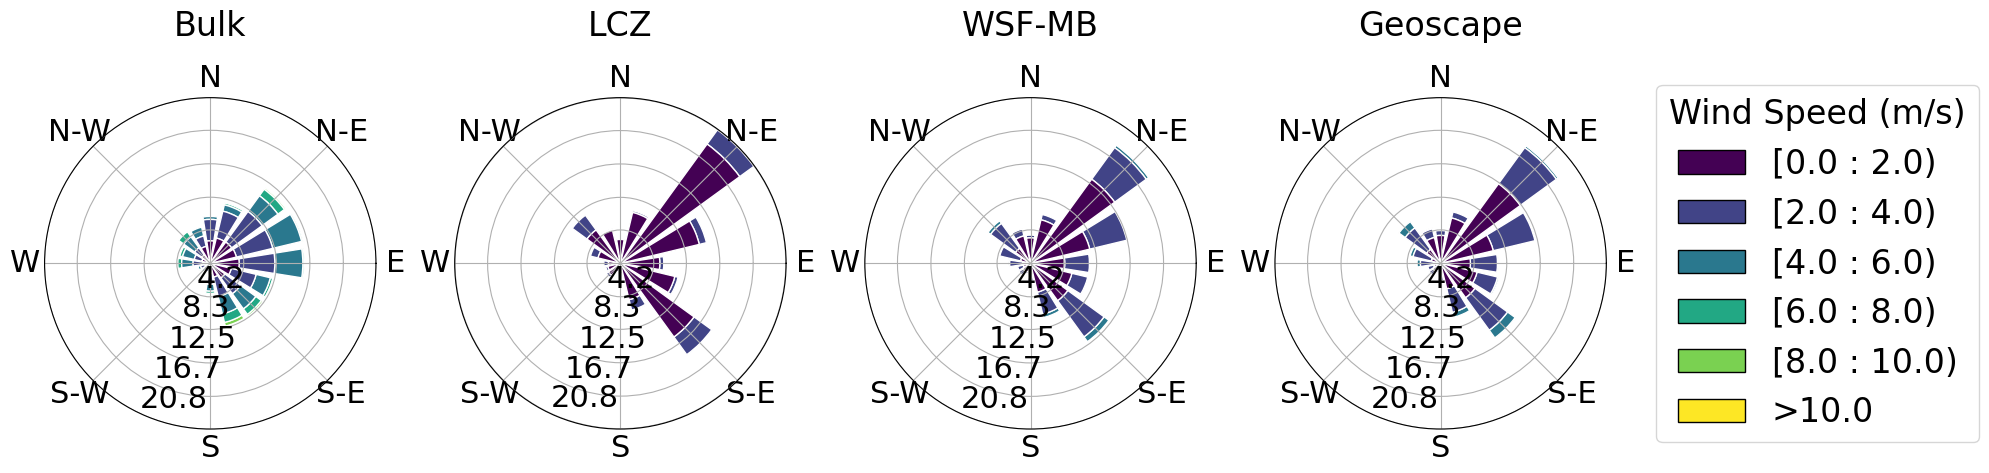


SUMMARY STATISTICS
Bulk:
  Data points: 392,589
  Mean wind speed: 3.12 m/s
  Max wind speed: 15.89 m/s
  Min wind speed: 0.00 m/s

LCZ:
  Data points: 392,589
  Mean wind speed: 1.21 m/s
  Max wind speed: 8.72 m/s
  Min wind speed: 0.00 m/s

WSF-MB:
  Data points: 392,589
  Mean wind speed: 1.78 m/s
  Max wind speed: 10.23 m/s
  Min wind speed: 0.00 m/s

Geoscape:
  Data points: 392,589
  Mean wind speed: 1.91 m/s
  Max wind speed: 10.22 m/s
  Min wind speed: 0.00 m/s



In [6]:
# Create the windrose plots (all urban points during the whole period/no averaging)
fig = plt.figure(figsize=(20, 5))

scenario_order = ["Bulk", "LCZ", "WSF-MB", "Geoscape"]

for i, scenario_name in enumerate(scenario_order):
    if scenario_name not in scenario_data:
        print(f"Skipping {scenario_name} - no data available")
        continue
        
    ax = fig.add_subplot(1, 4, i+1, projection="windrose")
    
    ws_data = scenario_data[scenario_name]['ws']
    wd_data = scenario_data[scenario_name]['wd']

    # Convert to pandas Series to use pandas methods for NaN detection
    ws_series = pd.Series(ws_data)

    # Calculate NaN statistics
    total_points = len(ws_data)
    nan_count = ws_series.isnull().sum()
    valid_count = ws_series.count()  # This counts non-NaN values
    
    print(f"Plotting {scenario_name}: {total_points} total data points, {nan_count} NaN points, {valid_count} valid points")
    
    ax.bar(wd_data, ws_data, normed=True, opening=0.8, edgecolor="white", bins=(0, 2, 4, 6, 8, 10))
    ax.set_title(scenario_name, fontsize=24, pad=20) #, fontweight='bold'
    # Set font sizes for windrose elements
    # Set fixed radial ticks
    ax.set_yticks([4.2, 8.3, 12.5, 16.7, 20.8])
    ax.set_yticklabels(['4.2', '8.3', '12.5', '16.7', '20.8'])
    ax.tick_params(axis='both', labelsize=22)  # For percentage labels
    # Move radial labels to the left (West = 245 degrees)
    ax.set_rlabel_position(245)
            
    # Set font size for direction labels (N, NE, E, etc.)
    for label in ax.get_xticklabels():
        label.set_fontsize(22)
                
    # Set font size for radial (percentage) labels  
    for label in ax.get_yticklabels():
        label.set_fontsize(22)
    
    # Add legend only for the last subplot
    if i == len(scenario_order) - 1:
        ax.legend(title='Wind Speed (m/s)', loc='center left', bbox_to_anchor=(1.1, 0.5), fontsize=24, title_fontsize=24)

plt.tight_layout()

plt.savefig('/g/data/gb02/mf9078/plots/windrose_all_scenarios_january.png', 
            dpi=300, bbox_inches='tight')

plt.show()

# Print summary statistics
print("\n" + "="*50)
print("SUMMARY STATISTICS")
print("="*50)
for scenario_name in scenario_order:
    if scenario_name in scenario_data:
        ws_data = scenario_data[scenario_name]['ws']
        print(f"{scenario_name}:")
        print(f"  Data points: {len(ws_data):,}")
        print(f"  Mean wind speed: {np.mean(ws_data):.2f} m/s")
        print(f"  Max wind speed: {np.max(ws_data):.2f} m/s")
        print(f"  Min wind speed: {np.min(ws_data):.2f} m/s")
        print()



In [7]:
# Data processing for each diurnal period
paths = {
    "Default(Bulk+NoUCM)": "/g/data/fy29/mf9078/run_WRF/etamodified/output/0out/",
    "LCZ": "/g/data/fy29/mf9078/run_WRF/etamodified/output/1out/",
    "WSF-MB": "/g/data/fy29/mf9078/run_WRF/etamodified/output/3out/animation/",
    "Geoscape": "/g/data/fy29/mf9078/run_WRF/etamodified/output/4out/"
}

time_periods = {
    "Before Sunrise": (2, 5),
    "Morning": (7, 10),
    "Peak Solar": (11, 14),
    "Afternoon": (15, 18),
    "Evening": (19, 22)
}

# Dictionary to store all wind data for each scenario and time period
scenario_period_data = {}

for scenario_name in paths.keys():
    scenario_period_data[scenario_name] = {}
    for period_name in time_periods.keys():
        scenario_period_data[scenario_name][period_name] = {
            'ws': [],
            'wd': []
        }

# Function to determine time period from AEST hour
def get_time_period(hour_aest):
    for period_name, (start_hour, end_hour) in time_periods.items():
        if start_hour <= hour_aest <= end_hour:
            return period_name
    return None

for scenario_name, path in paths.items():
    print(f"\nProcessing {scenario_name}...")
    
    file_pattern = os.path.join(path, "wrfout_d02_2017-01-*")
    file_list = sorted(glob.glob(file_pattern))
    print(f"Found {len(file_list)} files for {scenario_name}")
    
    for i, file_path in enumerate(file_list):
        try:
            # Extract time from filename and convert to AEST
            timestamp_utc = datetime.strptime(os.path.basename(file_path)[11:], "%Y-%m-%d_%H:%M:%S")
            timestamp_aest = timestamp_utc + timedelta(hours=10)
            hour_aest = timestamp_aest.hour
            
            # Determine which time period this file belongs to
            period_name = get_time_period(hour_aest)
            
            if period_name is None:
                continue  # Skip files that don't fall in any defined period
            
            ds = xr.open_dataset(file_path)
            
            # Calculate wind speed and direction
            U10 = ds["U10"]
            V10 = ds["V10"]
            ws = np.sqrt(U10**2 + V10**2)
            wd = 180 + (180 / np.pi) * np.arctan2(U10, V10)
            
            # Apply mask
            ws_masked = ws.where(region_mask).values
            wd_masked = wd.where(region_mask).values
            
            valid_mask = ~np.isnan(ws_masked)
            ws_valid = ws_masked[valid_mask]
            wd_valid = wd_masked[valid_mask]
            
            # Collect data for the appropriate time period
            scenario_period_data[scenario_name][period_name]['ws'].append(ws_valid)
            scenario_period_data[scenario_name][period_name]['wd'].append(wd_valid)
            
            ds.close()
            
        except Exception as e:
            print(f"Error processing {file_path}: {e}")
            continue

# Combine data for each scenario-period combination
for scenario_name in paths.keys():
    for period_name in time_periods.keys():
        ws_list = scenario_period_data[scenario_name][period_name]['ws']
        wd_list = scenario_period_data[scenario_name][period_name]['wd']
        
        if ws_list:
            combined_ws = np.concatenate(ws_list)
            combined_wd = np.concatenate(wd_list)
            
            scenario_period_data[scenario_name][period_name]['ws'] = combined_ws
            scenario_period_data[scenario_name][period_name]['wd'] = combined_wd
            
            print(f"{scenario_name} - {period_name}: {len(combined_ws)} data points")
        else:
            # No data for this combination
            scenario_period_data[scenario_name][period_name]['ws'] = np.array([])
            scenario_period_data[scenario_name][period_name]['wd'] = np.array([])
            print(f"{scenario_name} - {period_name}: No data points")



Processing Default(Bulk+NoUCM)...
Found 241 files for Default(Bulk+NoUCM)



Processing LCZ...
Found 241 files for LCZ

Processing WSF-MB...
Found 241 files for WSF-MB

Processing Geoscape...
Found 241 files for Geoscape
Default(Bulk+NoUCM) - Before Sunrise: 65160 data points
Default(Bulk+NoUCM) - Morning: 65160 data points
Default(Bulk+NoUCM) - Peak Solar: 65160 data points
Default(Bulk+NoUCM) - Afternoon: 65160 data points
Default(Bulk+NoUCM) - Evening: 65160 data points
LCZ - Before Sunrise: 65160 data points
LCZ - Morning: 65160 data points
LCZ - Peak Solar: 65160 data points
LCZ - Afternoon: 65160 data points
LCZ - Evening: 65160 data points
WSF-MB - Before Sunrise: 65160 data points
WSF-MB - Morning: 65160 data points
WSF-MB - Peak Solar: 65160 data points
WSF-MB - Afternoon: 65160 data points
WSF-MB - Evening: 65160 data points
Geoscape - Before Sunrise: 65160 data points
Geoscape - Morning: 65160 data points
Geoscape - Peak Solar: 65160 data points
Geoscape - Afternoon: 65160 data points
Geoscape - Evening: 65160 data points


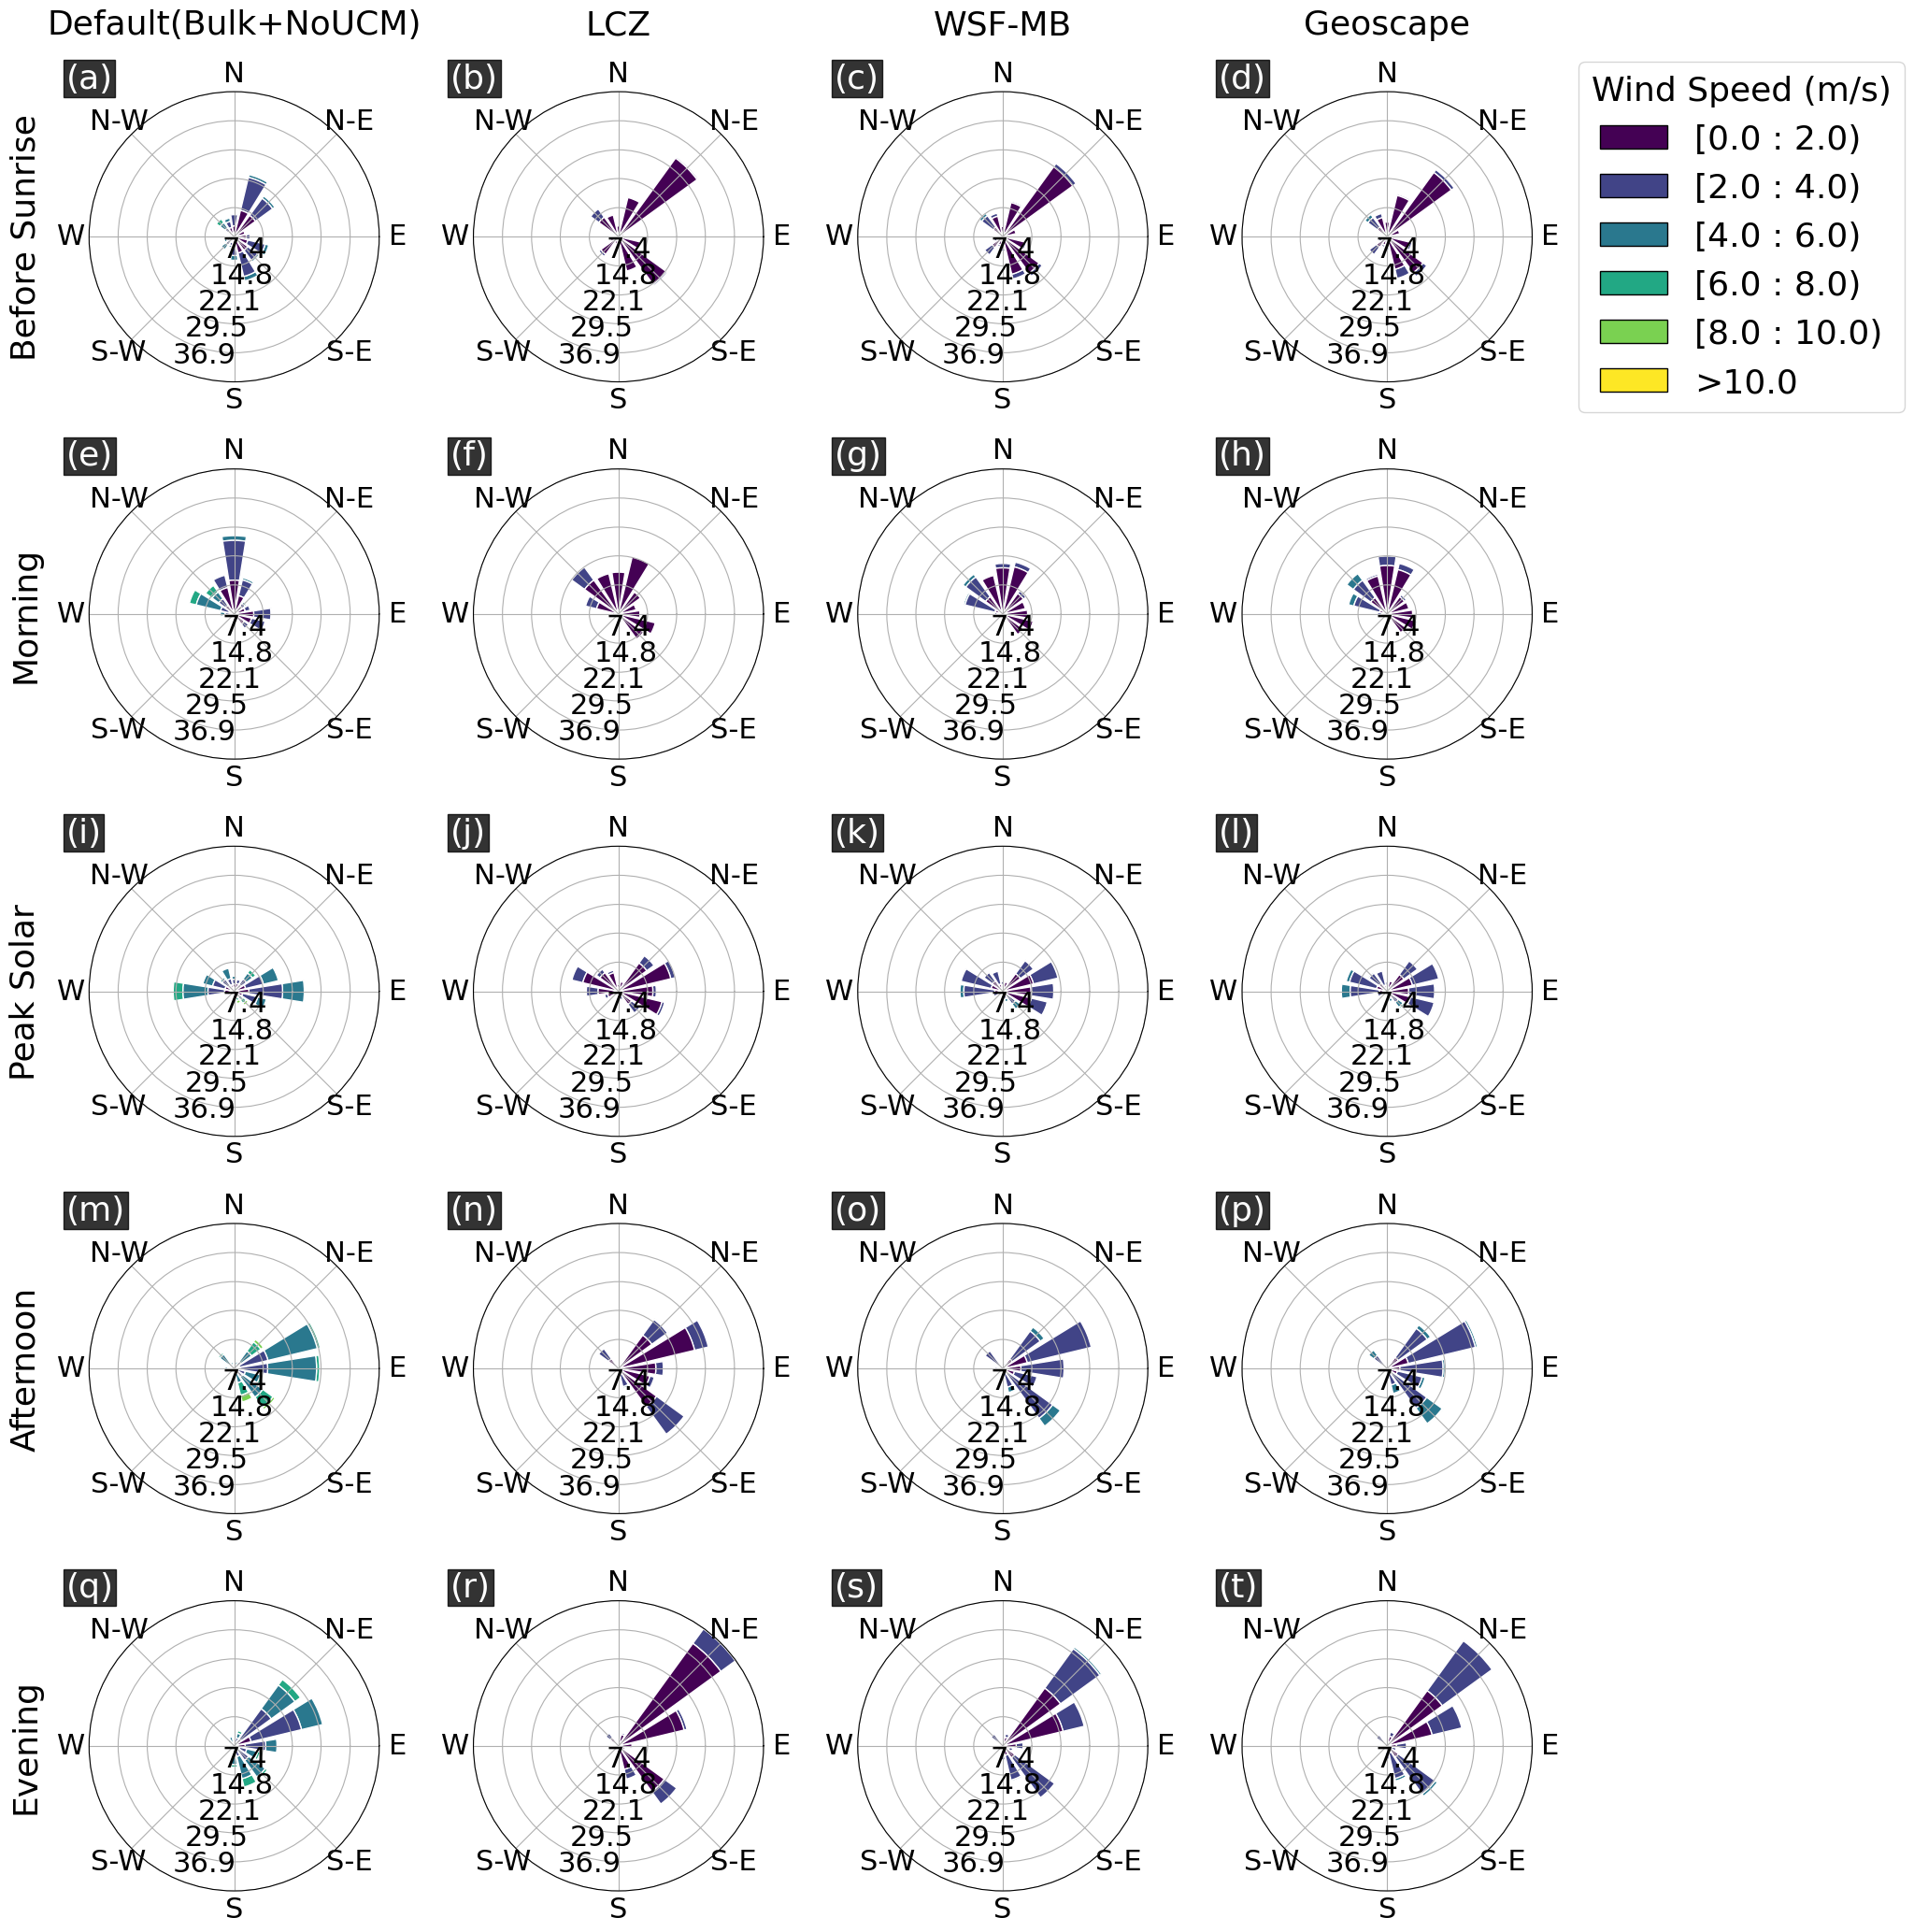


SUMMARY STATISTICS

BEFORE SUNRISE:
----------------------------------------
  Default(Bulk+NoUCM): 65,160 points, Mean WS:  2.30 m/s, Max WS:  9.72 m/s
  LCZ         : 65,160 points, Mean WS:  0.88 m/s, Max WS:  5.69 m/s
  WSF-MB      : 65,160 points, Mean WS:  1.20 m/s, Max WS:  6.40 m/s
  Geoscape    : 65,160 points, Mean WS:  1.28 m/s, Max WS:  6.47 m/s

MORNING:
----------------------------------------
  Default(Bulk+NoUCM): 65,160 points, Mean WS:  2.31 m/s, Max WS: 12.47 m/s
  LCZ         : 65,160 points, Mean WS:  0.94 m/s, Max WS:  6.63 m/s
  WSF-MB      : 65,160 points, Mean WS:  1.36 m/s, Max WS:  7.90 m/s
  Geoscape    : 65,160 points, Mean WS:  1.48 m/s, Max WS:  8.23 m/s

PEAK SOLAR:
----------------------------------------
  Default(Bulk+NoUCM): 65,160 points, Mean WS:  3.37 m/s, Max WS: 15.25 m/s
  LCZ         : 65,160 points, Mean WS:  1.44 m/s, Max WS:  8.72 m/s
  WSF-MB      : 65,160 points, Mean WS:  2.18 m/s, Max WS: 10.23 m/s
  Geoscape    : 65,160 points, Mean W

In [19]:
# Create the windrose plots (5 rows x 4 columns)
fig = plt.figure(figsize=(20, 25))

scenario_order = ["Default(Bulk+NoUCM)", "LCZ", "WSF-MB", "Geoscape"]
period_order = ["Before Sunrise", "Morning", "Peak Solar", "Afternoon", "Evening"]

subplot_counter = 1

for row, period_name in enumerate(period_order):
    for col, scenario_name in enumerate(scenario_order):
        # Create subplot with windrose projection
        ax = fig.add_subplot(5, 4, subplot_counter, projection="windrose")
        
        ws_data = scenario_period_data[scenario_name][period_name]['ws']
        wd_data = scenario_period_data[scenario_name][period_name]['wd']
        
        if len(ws_data) > 0:
            # Create windrose plot
            ax.bar(wd_data, ws_data, normed=True, opening=0.8, edgecolor="white", bins=(0, 2, 4, 6, 8, 10))
            
            # Set fixed radial ticks
            ax.set_yticks([7.4, 14.8, 22.1, 29.5, 36.9])
            ax.set_yticklabels(['7.4', '14.8', '22.1', '29.5', '36.9'])

            # Set font sizes for windrose elements
            ax.tick_params(axis='both', labelsize=22)  # For percentage labels
            
            # Set font size for direction labels (N, NE, E, etc.)
            for label in ax.get_xticklabels():
                label.set_fontsize(22)
                
            # Set font size for radial (percentage) labels  
            for label in ax.get_yticklabels():
                label.set_fontsize(22)

            # Move radial labels to the left (West = 245 degrees)
            ax.set_rlabel_position(245)
        
        else:
            # No data available - create empty plot with text
            ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes, 
                   ha='center', va='center', fontsize=22, fontweight='bold')
        
        # Set title for first row (scenarios)
        if row == 0:
            ax.set_title(scenario_name, fontsize=26, pad=20) #fontweight='bold', 
        
        # Set ylabel for first column (time periods)
        if col == 0:
            ax.text(-0.22, 0.5, period_name, transform=ax.transAxes, 
                   rotation=90, ha='center', va='center', 
                   fontsize=26) #, fontweight='bold'
        
        # Add legend only for the top-Marright subplot
        if row == 0 and col == len(scenario_order) - 1:
            ax.legend(title='Wind Speed (m/s)', loc='center left', bbox_to_anchor=(1.1, 0.5), fontsize=26, title_fontsize=26)

        # Subplot label (a)-(t), left to right then top to bottom
        ax.text(-0.08, 1.1, f"({chr(ord('a') + subplot_counter - 1)})",
                transform=ax.transAxes, fontsize=26, #fontweight="bold", 
                ha="left", va="top", color="white", zorder=10,
                bbox=dict(facecolor="black", edgecolor="black", alpha=0.8, pad=2))        
        
        subplot_counter += 1

# Create a dummy windrose to get legend handles
dummy_ax = fig.add_subplot(111, projection="windrose", frame_on=False)
dummy_ax.bar([0, 90, 180, 270], [1, 2, 3, 4], normed=True, opening=0.8, edgecolor="white")
handles, labels = dummy_ax.get_legend_handles_labels()
dummy_ax.remove()  # Remove the dummy subplot

plt.subplots_adjust(hspace=0.3, wspace=0.3) 

plt.savefig('Fig8.png', 
            dpi=300, bbox_inches='tight')

plt.show()

# Print summary statistics
print("\n" + "="*80)
print("SUMMARY STATISTICS")
print("="*80)
for period_name in period_order:
    print(f"\n{period_name.upper()}:")
    print("-" * 40)
    for scenario_name in scenario_order:
        ws_data = scenario_period_data[scenario_name][period_name]['ws']
        if len(ws_data) > 0:
            print(f"  {scenario_name:12}: {len(ws_data):6,} points, "
                  f"Mean WS: {np.mean(ws_data):5.2f} m/s, "
                  f"Max WS: {np.max(ws_data):5.2f} m/s")
        else:
            print(f"  {scenario_name:12}: No data points")